# 06 · Hub-centrality contrast across topologies (exploratory)

**Reviewer question this addresses:** the paper states that in ER/WS "most-connected nodes are not genuine hubs" as the reason the backfire effect vanishes there, but supports it with a single sentence. The reviewer asks for a quantitative comparison of the manipulated target's actual in-degree / betweenness centrality, before vs after manipulation, across CNNR/HK vs ER/WS — especially since follow/unfollow dynamics (followee cap = 10, no follower cap) could in principle grow endogenous hubs even in ER/WS.

**Scope of this notebook:** exploratory only, run at the user's request to check the numbers before deciding whether/how to fold anything into `docs/journal-June.tex`. No LaTeX is edited here. No new simulations are run — everything below is read from the existing degree-aligned sweep (`results/summary/**/config.yaml` + `target_hub_metrics_5000step.csv` + `connectivity_5000step.csv`), 125 conditions total (25 each: CNNR, ER, WS, HK pt=0.0, HK pt=0.3).

**Manipulation timing:** onset at step 20000 (target identified once from the step-20000 GEXF and tracked by node id thereafter — see `notebooks/00_build_summary.ipynb` Item 7); comparisons below use `step=20000` (pre/onset) vs `step=40000` (final, post-manipulation).

**Metrics:**
- `in_degree`, `betweenness_gc` (undirected, giant-component betweenness — the corrected metric from `betweenness-directed-bug`; full-graph directed betweenness is invalid for this follow-graph) from `target_hub_metrics_5000step.csv`.
- `target_is_ap` (is the target an articulation point of the undirected giant component) and `delta_lambda2` (change in giant-component algebraic connectivity if the target is removed) from `connectivity_5000step.csv` — these answer "was the target ever load-bearing for global connectivity," independent of its own degree.
- `n_valid` from `selected_seeds.json` — how many seeds/25 conditions actually yielded an eligible manipulation target (follower count ≥ 10% of population), for context on the reviewer's "candidates obtained in substantial numbers in ER/WS" point.

In [1]:
# --- bootstrap: run from anywhere; cd to repo root (has results/ and src/) ---
import os
for _ in range(5):
    if os.path.isdir('results') and os.path.isdir('src'):
        break
    os.chdir('..')
print('working dir:', os.getcwd())

working dir: /home/tomoyatakeda/document/research/manipulation-backfire-model


In [2]:
import glob
import json
import warnings

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.size': 11, 'axes.titlesize': 12,
})

SUMMARY_ROOT = './results/summary'
ONSET_STEP, POST_STEP = 20000, 40000


def make_nw_label(topology: str, net_params: dict) -> str:
    """Identical convention to notebooks/05_sensitivity_dose_response.ipynb,
    so labels are directly comparable across notebooks."""
    if not net_params:
        return topology
    param_str = ', '.join(f'{k}={v}' for k, v in sorted(net_params.items()))
    return f'{topology} ({param_str})'


print('Helpers defined.')

Helpers defined.


## 1. Scan all 125 conditions

For each condition directory we pull:
- `target_hub_metrics_5000step.csv` → `in_degree`, `betweenness_gc` at onset (step 20000) and post (step 40000), joined per (seed, target_sign).
- `connectivity_5000step.csv` → `target_is_ap`, `delta_lambda2` at the same two steps.
- `selected_seeds.json` → `n_valid` (how many seeds cleared the ≥10%-follower-share eligibility bar for this condition).

In [3]:
rows_hub, rows_conn, rows_seeds = [], [], []
skipped = []

cfg_paths = sorted(glob.glob(os.path.join(SUMMARY_ROOT, '*', '*', '*', 'config.yaml')))
print(f'Found {len(cfg_paths)} condition dir(s).')

for cfg_path in cfg_paths:
    cond_dir = os.path.dirname(cfg_path)
    hash_id = os.path.basename(cond_dir)
    with open(cfg_path) as f:
        cfg = yaml.safe_load(f)
    topology = cfg.get('topology', 'Unknown')
    net_params = cfg.get('network_params', {})
    mu, epsilon_s = cfg.get('mu'), cfg.get('epsilon_s')
    nw_label = make_nw_label(topology, net_params)

    hub_path = os.path.join(cond_dir, 'target_hub_metrics_5000step.csv')
    if os.path.exists(hub_path):
        df = pd.read_csv(hub_path)
        onset = (df[df.step == ONSET_STEP][['seed', 'target_sign', 'in_degree', 'betweenness_gc']]
                 .rename(columns={'in_degree': 'indeg_onset', 'betweenness_gc': 'btw_onset'}))
        post = (df[df.step == POST_STEP][['seed', 'target_sign', 'in_degree', 'betweenness_gc']]
                .rename(columns={'in_degree': 'indeg_post', 'betweenness_gc': 'btw_post'}))
        j = onset.merge(post, on=['seed', 'target_sign'], how='inner')
        if not j.empty:
            j['topology'], j['nw_label'] = topology, nw_label
            j['mu'], j['epsilon_s'], j['hash_id'] = mu, epsilon_s, hash_id
            rows_hub.append(j)
    else:
        skipped.append((hash_id, 'no target_hub_metrics'))

    conn_path = os.path.join(cond_dir, 'connectivity_5000step.csv')
    if os.path.exists(conn_path):
        dc = pd.read_csv(conn_path)
        onset = (dc[dc.step == ONSET_STEP][['seed', 'target_sign', 'target_is_ap', 'delta_lambda2']]
                 .rename(columns={'target_is_ap': 'ap_onset', 'delta_lambda2': 'dl_onset'}))
        post = (dc[dc.step == POST_STEP][['seed', 'target_sign', 'target_is_ap', 'delta_lambda2']]
                .rename(columns={'target_is_ap': 'ap_post', 'delta_lambda2': 'dl_post'}))
        j2 = onset.merge(post, on=['seed', 'target_sign'], how='inner')
        if not j2.empty:
            j2['topology'], j2['nw_label'] = topology, nw_label
            j2['mu'], j2['epsilon_s'], j2['hash_id'] = mu, epsilon_s, hash_id
            rows_conn.append(j2)
    else:
        skipped.append((hash_id, 'no connectivity'))

    seeds_path = os.path.join(cond_dir, 'selected_seeds.json')
    if os.path.exists(seeds_path):
        with open(seeds_path) as f:
            sj = json.load(f)
        rows_seeds.append({'topology': topology, 'nw_label': nw_label, 'hash_id': hash_id,
                            'mu': mu, 'epsilon_s': epsilon_s, 'n_valid': sj.get('n_valid')})

df_hub = pd.concat(rows_hub, ignore_index=True)
df_conn = pd.concat(rows_conn, ignore_index=True)
df_seeds = pd.DataFrame(rows_seeds)

# Stable topology ordering / color palette, same convention as notebook 05
TOPO_ORDER = sorted(df_hub['nw_label'].unique(),
                     key=lambda s: (s.split(' ')[0] != 'HolmeKim', s))
_BASE_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
NW_COLOR = {nw: _BASE_COLORS[i % len(_BASE_COLORS)] for i, nw in enumerate(TOPO_ORDER)}

print(f'df_hub: {df_hub.shape}, df_conn: {df_conn.shape}, df_seeds: {df_seeds.shape}')
if skipped:
    print(f'Skipped: {skipped}')
print('\nTopologies:', TOPO_ORDER)

Found 125 condition dir(s).


df_hub: (12182, 11), df_conn: (12182, 11), df_seeds: (125, 6)

Topologies: ['HolmeKim (A=1, m=2, pt=0.0)', 'HolmeKim (A=1, m=2, pt=0.3)', 'CNNR (p=0.5, r=0.01)', 'ER (p=0.002)', 'WS (K=4, beta=0.1)']


## 2. Does a heavy tail actually emerge by manipulation onset? (not just at generation)

Table 2 in the paper reports the degree distribution at **generation** (step 0,
before any follow/unfollow dynamics): CNNR/HK are heavy-tailed there, ER/WS are
not. The reviewer's objection is specifically that the dynamics (followee cap
10, no follower cap) could grow a heavy tail **endogenously** by the time
manipulation happens at step 20000, even in ER/WS — so the generation-time
table alone doesn't settle it. This section re-runs the same check (fitted
degree-distribution exponent `gamma`, self-rolled MLE from
`notebooks/00_build_summary.ipynb`, same caveats as `nwmetrics-table-method` —
directional comparison across topologies, not a strict power-law identification)
at **step 20000 itself**, from `nw_stats_5000step.csv`.

In [4]:
rows_nw = []
for cfg_path in cfg_paths:
    cond_dir = os.path.dirname(cfg_path)
    with open(cfg_path) as f:
        cfg = yaml.safe_load(f)
    nw_label = make_nw_label(cfg.get('topology', 'Unknown'), cfg.get('network_params', {}))
    nw_path = os.path.join(cond_dir, 'nw_stats_5000step.csv')
    if not os.path.exists(nw_path):
        continue
    dn = pd.read_csv(nw_path)
    for step in (0, ONSET_STEP):
        on = dn[dn.step == step]
        if on.empty:
            continue
        rows_nw.append({'nw_label': nw_label, 'step': step,
                         'gamma': on.gamma.mean(), 'mean_in_degree': on.mean_in_degree.mean()})

df_nw = pd.DataFrame(rows_nw)
tbl_nw = (df_nw.groupby(['nw_label', 'step'])[['gamma', 'mean_in_degree']]
          .mean().unstack('step').reindex(TOPO_ORDER))
tbl_nw

gamma           mean_in_degree          
step                            0         20000          0         20000
nw_label                                                                
HolmeKim (A=1, m=2, pt=0.0)  2.209616  1.801372       2.000000  4.157121
HolmeKim (A=1, m=2, pt=0.3)  2.002755  1.783326       2.000000  3.464550
CNNR (p=0.5, r=0.01)         2.378792  1.939504       1.999909  4.547368
ER (p=0.002)                 1.720059  4.092254       2.000782  6.424796
WS (K=4, beta=0.1)           1.741755  3.831269       2.000000  8.583673

**Reading this table**: `gamma` ≈ 1.8–1.9 in CNNR/HK at step 20000 (essentially
unchanged from generation, and matching the Table-2 HK value of ≈1.95 —
[[nwmetrics-table-method]]) vs `gamma` ≈ 3.8–4.1 in ER/WS at step 20000 (much
higher = much faster tail decay = thin-tailed), while `mean_in_degree` is
actually *higher* in ER/WS at onset (6.4–8.6) than in CNNR/HK (3.5–4.5) — i.e.
ER/WS spread new edges more evenly across many nodes rather than concentrating
them.

**This directly answers "does a heavy tail emerge through the dynamics":
no — the whole-network degree distribution stays statistically thin-tailed in
ER/WS all the way to manipulation onset**, not just at generation. That is the
simple, primary fact and should be the paper's main line of defense (it extends
Table 2 to step 20000 instead of resting only on step 0).

It does not, by itself, explain why a node satisfying the ≥10%-follower
*eligibility* criterion can still be found in ER/WS (Section 5 below) — that
criterion is a **relative** threshold (top of whatever local distribution
exists), so a thin-tailed distribution with elevated mean degree can still
produce a node crossing it, without that node being a genuine hub. Section 4
(target-is-articulation-point) is the direct test of *that* residual question:
is the node found this way structurally unique, or just the unremarkable top of
a crowd of similarly-connected peers?

## 3. Target in-degree / betweenness, onset vs post — by topology

Paired onset→post comparison, clustered at the (condition, seed) level (mean over
the two `target_sign` directions, which share one network realization — same
clustering logic as `cluster_stats` in notebook 05) before the Wilcoxon
signed-rank test. `frac_zero_post` is the fraction of trials where the target's
in-degree is **exactly 0** at step 40000 (complete unfollowing, not just decline).

In [5]:
def cluster_pair_stats(df, on_col, post_col):
    """Seed-clustered (condition, seed) means, paired Wilcoxon onset vs post.
    Returns (mean_onset, mean_post, median_onset, median_post, p_value, n_clusters)."""
    g = df.groupby(['hash_id', 'seed'])[[on_col, post_col]].mean()
    if len(g) > 5:
        p = stats.wilcoxon(g[on_col], g[post_col]).pvalue
    else:
        p = np.nan
    return (g[on_col].mean(), g[post_col].mean(),
            g[on_col].median(), g[post_col].median(), p, len(g))


hub_rows = []
for label in TOPO_ORDER:
    sub = df_hub[df_hub.nw_label == label]
    if sub.empty:
        continue
    indeg_on_m, indeg_po_m, indeg_on_md, indeg_po_md, p_indeg, n_cl = cluster_pair_stats(
        sub, 'indeg_onset', 'indeg_post')
    btw_on_m, btw_po_m, btw_on_md, btw_po_md, p_btw, _ = cluster_pair_stats(
        sub, 'btw_onset', 'btw_post')
    hub_rows.append({
        'nw_label': label, 'n_cond': sub.hash_id.nunique(), 'n_seed_clusters': n_cl,
        'indeg_onset_mean': indeg_on_m, 'indeg_post_mean': indeg_po_m,
        'indeg_onset_median': indeg_on_md, 'indeg_post_median': indeg_po_md,
        'frac_zero_post': (sub.indeg_post == 0).mean(),
        'p_wilcoxon_indeg': p_indeg,
        'btw_gc_onset_mean': btw_on_m, 'btw_gc_post_mean': btw_po_m,
        'p_wilcoxon_btw': p_btw,
    })

tbl_hub = pd.DataFrame(hub_rows).set_index('nw_label')
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
tbl_hub

,n_cond,n_seed_clusters,indeg_onset_mean,indeg_post_mean,indeg_onset_median,indeg_post_median,frac_zero_post,p_wilcoxon_indeg,btw_gc_onset_mean,btw_gc_post_mean,p_wilcoxon_btw
nw_label,,,,,,,,,,,
"HolmeKim (A=1, m=2, pt=0.0)",25,1250,291.2144,72.7264,224.0000,49.5000,0.0080,0.0000,0.1294,0.0250,0.0000
"HolmeKim (A=1, m=2, pt=0.3)",25,1130,316.9761,96.1199,195.0000,50.5000,0.0013,0.0000,0.1639,0.0482,0.0000
"CNNR (p=0.5, r=0.01)",25,1250,288.9472,90.5680,191.0000,57.0000,0.0072,0.0000,0.1478,0.0812,0.0000
ER (p=0.002),25,1215,141.9374,2.5152,129.0000,0.5000,0.6206,0.0000,0.0437,0.0011,0.0000
"WS (K=4, beta=0.1)",25,1246,182.5165,2.5506,159.0000,0.5000,0.6994,0.0000,0.0413,0.0007,0.0000


## 4. Was the target ever load-bearing for global connectivity?

`in_degree`/`betweenness_gc` describe the target's *own* connections. This section
asks a different question: independent of how connected the target itself is,
did removing it ever matter for the *whole* giant component? `target_is_ap` = 1
means the target is an articulation point (removing it disconnects the giant
component); `delta_lambda2` = λ₂(G) − λ₂(G − target). Both are computed at onset
**and** post so we can see whether the target was ever a bridge in the first
place, not only whether it stops being one.

In [6]:
conn_rows = []
for label in TOPO_ORDER:
    sub = df_conn[df_conn.nw_label == label]
    if sub.empty:
        continue
    conn_rows.append({
        'nw_label': label,
        'target_is_ap_onset': sub.ap_onset.mean(),
        'target_is_ap_post': sub.ap_post.mean(),
        'abs_delta_lambda2_onset': sub.dl_onset.abs().mean(),
        'abs_delta_lambda2_post': sub.dl_post.abs().mean(),
    })

tbl_conn = pd.DataFrame(conn_rows).set_index('nw_label')
tbl_conn

,target_is_ap_onset,target_is_ap_post,abs_delta_lambda2_onset,abs_delta_lambda2_post
nw_label,,,,
"HolmeKim (A=1, m=2, pt=0.0)",0.7080,0.3624,0.0183,0.0058
"HolmeKim (A=1, m=2, pt=0.3)",0.7345,0.4628,0.0267,0.0079
"CNNR (p=0.5, r=0.01)",0.5232,0.5208,0.0380,0.0216
ER (p=0.002),0.0593,0.0695,0.0003,0.0001
"WS (K=4, beta=0.1)",0.0000,0.0449,0.0055,0.0025


## 5. Eligible-candidate retention (context for the reviewer's "N=50" remark)

`n_valid` = number of seeds (out of the attempted pool) per condition for which
at least one agent cleared the ≥10%-follower-share eligibility bar (tex line
~603). This is a different question from Sections 2–3 (it's about whether a
target *could be selected at all*, not how central the selected target turns
out to be) but is the quantity the reviewer's parenthetical seems to reference.

In [7]:
tbl_seeds = (df_seeds.groupby('nw_label')['n_valid']
             .agg(['mean', 'min', 'max', 'count'])
             .reindex(TOPO_ORDER))
tbl_seeds.rename(columns={'count': 'n_conditions'})

,mean,min,max,n_conditions
nw_label,,,,
"HolmeKim (A=1, m=2, pt=0.0)",65.8800,51,94,25
"HolmeKim (A=1, m=2, pt=0.3)",53.1600,37,94,25
"CNNR (p=0.5, r=0.01)",68.8000,62,75,25
ER (p=0.002),70.2000,38,80,25
"WS (K=4, beta=0.1)",74.5600,46,80,25


## 6. Figures

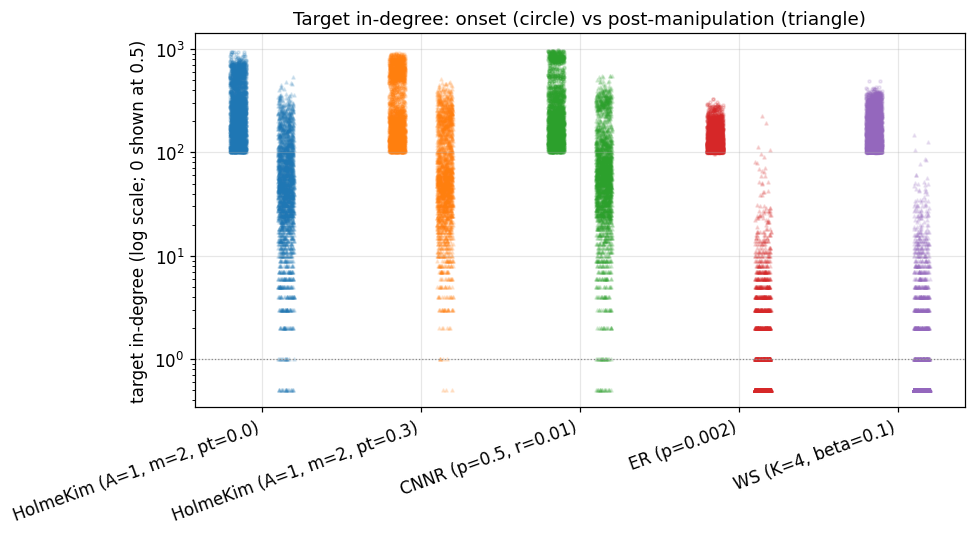

In [8]:
# (a) In-degree onset vs post, log scale (jittered strip, one column pair per topology)
fig, ax = plt.subplots(figsize=(9, 5))
rng = np.random.default_rng(0)
xt = []
for i, label in enumerate(TOPO_ORDER):
    sub = df_hub[df_hub.nw_label == label]
    for j, (col, dx) in enumerate([('indeg_onset', -0.15), ('indeg_post', 0.15)]):
        y = sub[col].clip(lower=0.5)  # so exact zeros are visible on log scale
        x = i + dx + rng.uniform(-0.05, 0.05, size=len(y))
        ax.scatter(x, y, s=4, alpha=0.15, color=NW_COLOR[label],
                   marker='o' if j == 0 else '^', rasterized=True)
    xt.append(i)
ax.set_yscale('log')
ax.set_xticks(xt)
ax.set_xticklabels(TOPO_ORDER, rotation=20, ha='right')
ax.set_ylabel('target in-degree (log scale; 0 shown at 0.5)')
ax.set_title('Target in-degree: onset (circle) vs post-manipulation (triangle)')
ax.axhline(1, color='#888888', ls=':', lw=0.8)
plt.tight_layout()
plt.show()

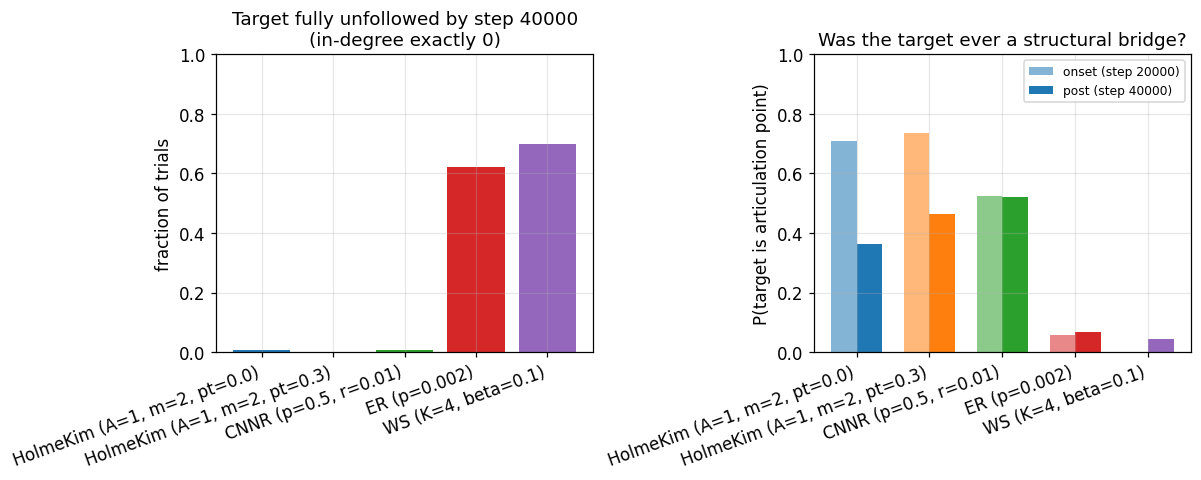

In [9]:
# (b) Fraction of trials with in_degree == 0 at post, and target_is_ap onset vs post
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

frac_zero = tbl_hub['frac_zero_post'].reindex(TOPO_ORDER)
axes[0].bar(range(len(TOPO_ORDER)), frac_zero.values,
            color=[NW_COLOR[l] for l in TOPO_ORDER])
axes[0].set_xticks(range(len(TOPO_ORDER)))
axes[0].set_xticklabels(TOPO_ORDER, rotation=20, ha='right')
axes[0].set_ylabel('fraction of trials')
axes[0].set_title('Target fully unfollowed by step 40000\n(in-degree exactly 0)')
axes[0].set_ylim(0, 1)

w = 0.35
x = np.arange(len(TOPO_ORDER))
ap_onset = tbl_conn['target_is_ap_onset'].reindex(TOPO_ORDER)
ap_post = tbl_conn['target_is_ap_post'].reindex(TOPO_ORDER)
axes[1].bar(x - w/2, ap_onset.values, w, label='onset (step 20000)',
            color=[NW_COLOR[l] for l in TOPO_ORDER], alpha=0.55)
axes[1].bar(x + w/2, ap_post.values, w, label='post (step 40000)',
            color=[NW_COLOR[l] for l in TOPO_ORDER], alpha=1.0)
axes[1].set_xticks(x)
axes[1].set_xticklabels(TOPO_ORDER, rotation=20, ha='right')
axes[1].set_ylabel('P(target is articulation point)')
axes[1].set_title('Was the target ever a structural bridge?')
axes[1].legend(fontsize=8)
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 7. Reading the result (fill in / correct after running)

**Primary, simple answer (Section 2)**: a heavy tail never emerges in ER/WS —
not just at generation (Table 2) but all the way through to manipulation onset
at step 20000 (fitted `gamma` ≈ 3.8–4.1 in ER/WS vs ≈ 1.8–1.9 in CNNR/HK, the
latter matching Table 2's HK ≈ 1.95). This is the direct, quantitative rebuttal
to the reviewer's specific worry that the follow/unfollow dynamics could grow a
hub structure endogenously regardless of initial topology — they don't.

**The residual question this alone doesn't answer**: the manipulation-target
eligibility rule is a *relative* threshold (≥10% follower share), so even a
thin-tailed distribution produces *some* node crossing it (confirmed:
n_valid ≈ 70–75/25 conditions in ER/WS, Section 5) — that's not evidence of an
emergent hub, just the natural top of a more evenly-spread distribution (mean
in-degree at onset is in fact *higher* in ER/WS than in CNNR/HK). Sections 3–4
show what that means concretely for the *specific* selected node:

- **Onset absolute levels (Section 3)**: ER/WS target in-degree is already lower
  on average than CNNR/HK at onset (~130–180 vs ~290–320), even though mean
  degree is matched (`<k>=4`) across all five networks.
- **Post-manipulation magnitude, NOT direction, differs sharply (Section 3)**:
  in-degree and `betweenness_gc` decline in *every* topology after manipulation
  (unfollowing happens everywhere) — but in ER/WS the decline goes essentially
  all the way to **zero** (≈60–70% of trials hit in-degree == 0 exactly, vs
  ≈0–1% in CNNR/HK). So "ER/WS targets don't lose centrality" would be the
  **wrong** framing — they lose *more*, not less.
- **The load-bearing test is where the topologies actually separate
  (Section 4)**: `target_is_ap` shows the ER/WS target was essentially *never*
  an articulation point even before manipulation (~0–7%), and `delta_lambda2`
  is ~0 throughout — vs CNNR/HK where the target starts as a bridge in a
  sizeable fraction of trials (~52–74%) and that fraction drops after
  manipulation. Because the whole distribution is thin-tailed (Section 2), the
  ER/WS target always has many near-equally-connected peers providing
  redundant paths, so removing/isolating it changes nothing about the giant
  component's connectivity, regardless of how completely it gets unfollowed.

**Proposed reframing of the one-sentence claim, if the numbers above hold up**:
lead with the distributional fact — "the degree distribution in ER/WS remains
statistically thin-tailed through manipulation onset, not only at generation
(gamma ≈ 3.8–4.1 vs ≈ 1.8–1.9)" — and use the articulation-point result as the
mechanistic explanation for *why* that matters: a thin tail means no node is
structurally unique, so even a locally high-follower node is never a bridge
(AP rate ~0–7% vs ~52–74%; Δλ₂ ≈ 0 throughout), and severing it — however
completely — has no consequence for the network's connectivity.

**Caveats / open questions before this goes into the paper:**
1. This is still partly a **target-local** story for Sections 3–4. It does not
   yet show the *aggregate* consequence claimed in the mechanism section
   (echo-chamber formation, posting-rate change) is similarly absent in ER/WS —
   that would need the `crate`/`follower_crate_proxy` analogue of notebook 04
   run per-topology, which is out of scope here.
2. `target_is_ap` and `delta_lambda2` are computed on the **giant component**
   only (per `betweenness-directed-bug`); worth double-checking giant-component
   size as a fraction of N is comparable across topologies, otherwise "P(AP)"
   isn't measuring the same thing everywhere.
3. `gamma` here is the crude self-rolled MLE (same one flagged with an honesty
   caveat in `nwmetrics-table-method`: not validated against a lognormal
   alternative). Treat it as a directional discriminator between topologies,
   not a strict "power-law confirmed" claim — same caveat as Table 2.
4. Multiple-comparison correction not applied here (this is a descriptive
   contrast across 5 topology groups, not a per-cell significance grid like
   notebook 05) — the Wilcoxon p-values are there for scale, not as a claim.
5. Decide with the user: does the "60–70% reach in-degree 0" fact belong in the
   main text at all, or is it better left implicit and only the gamma / AP / Δλ₂
   contrast surfaced (since the in-degree-0 fact, read carelessly, could look
   like it *undercuts* "not genuine hubs" rather than supporting it)?